# Symmetry, photonics-inspired edges, and crack detection

This notebook walks through the `crack_photonics` package from the physics up.

| Section | Question |
|---|---|
| 1 | Where does the "photonics" come from? |
| 2 | What is image symmetry, and how do we measure it? |
| 3 | How do we turn a picture into crack measurements? |
| 4 | How long does it take, and how does that grow with image size? |
| 5 | How is a physics-inspired algorithm different from a neural network? |

**Read this first.** Everything here runs on a CPU with synthetic test images.
The edge detector is a *simplified educational approximation* of the Phase
Stretch Transform; it does not reproduce laboratory photonic hardware. The
numbers are for learning, not for deciding whether a structure is safe.

In [1]:
import sys
from pathlib import Path

# Make the package importable when the notebook is run from notebooks/
# without `pip install -e .`.
src = Path.cwd().parent / "src"
if src.is_dir() and str(src) not in sys.path:
    sys.path.insert(0, str(src))

import numpy as np
import matplotlib.pyplot as plt

import crack_photonics
from crack_photonics import io, symmetry, pst_edges, crack_metrics
from crack_photonics.cli import analyze
from crack_photonics.timing import StageTimer, STAGE_NAMES

SEED = crack_photonics.DEFAULT_SEED   # one fixed seed for the whole notebook
plt.rcParams["figure.dpi"] = 90
print("crack_photonics", crack_photonics.__version__, "| seed =", SEED)

crack_photonics 0.1.0 | seed = 0


## 1. Physical motivation

### Dispersion: a filter that only changes phase

When a short light pulse travels through a long glass fibre, its colours
travel at slightly different speeds. Nothing is absorbed; the colours are
just *delayed* by different amounts. In the frequency domain that is a pure
phase filter:

$$
\tilde E_{\text{out}}(\omega)=\tilde E_{\text{in}}(\omega)\,e^{-j\varphi(\omega)},
\qquad
\tau_g(\omega)=\frac{d\varphi}{d\omega}\quad\text{(group delay)} .
$$

Photonic time-stretch instruments use a large, known dispersion to spread a
fast signal out in time so that ordinary electronics can record it.

### The Phase Stretch Transform (PST) idea

Asghari and Jalali asked what happens if you apply the same kind of filter to
an *image*, with spatial frequency $(u,v)$ in place of optical frequency:

1. Fourier transform the image.
2. Multiply by $e^{-j\varphi(r)}$ with $r=\sqrt{u^2+v^2}$ and a phase that
   grows with $r$.
3. Transform back and keep the **phase** of the result.

Flat regions contain only low frequencies, which receive almost no phase, so
the output phase is near zero. Edges contain high frequencies, which receive a
large phase. The output phase is therefore an edge map.

The phase profile used here is

$$
\varphi(r)=S\;\frac{Wr\arctan(Wr)-\tfrac12\ln\!\bigl(1+(Wr)^2\bigr)}{\max(\cdot)},
\qquad
\frac{d\varphi}{dr}\propto\arctan(Wr),
$$

with strength $S$ and warp $W$. The group delay $\arctan(Wr)$ rises linearly
for small $r$ and saturates for large $r$.

> **Honest label.** `crack_photonics.pst_edges` is about forty lines of
> NumPy/SciPy written from these equations. It is a digital filter *inspired
> by* dispersion. No laser, fibre or optical bench is involved or required.

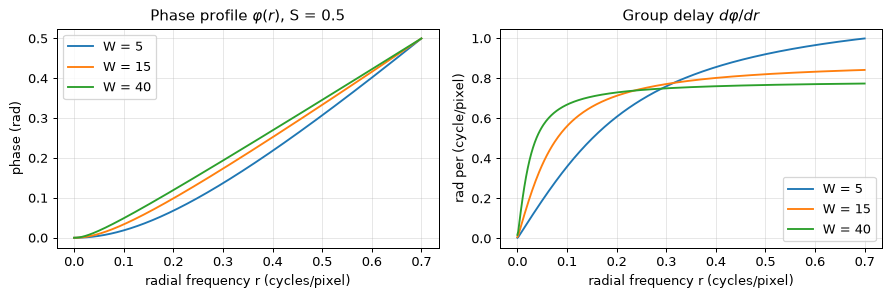

package kernel: phi(0) = 0.0  max = 0.5


In [2]:
r = np.linspace(0, 0.7, 400)                       # cycles per pixel
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for W in (5, 15, 40):
    wr = W * r
    phi = wr * np.arctan(wr) - 0.5 * np.log1p(wr**2)
    phi = 0.5 * phi / phi.max()
    axes[0].plot(r, phi, label=f"W = {W}")
    axes[1].plot(r, np.gradient(phi, r), label=f"W = {W}")
axes[0].set(title=r"Phase profile $\varphi(r)$, S = 0.5", xlabel="radial frequency r (cycles/pixel)", ylabel="phase (rad)")
axes[1].set(title=r"Group delay $d\varphi/dr$", xlabel="radial frequency r (cycles/pixel)", ylabel="rad per (cycle/pixel)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

# The kernel the package actually uses is the same curve on the 2-D FFT grid.
kernel = pst_edges.pst_phase_kernel((64, 64))
print("package kernel: phi(0) =", kernel[0, 0], " max =", kernel.max())

## 2. Image symmetry

### Reflection is a parity operator

Let $P$ mirror an image left $\leftrightarrow$ right: $(PI)(x,y)=I(-x,y)=I_R$.
Mirroring twice does nothing, $P^2=1$, so $P$ has only two eigenvalues,
$+1$ and $-1$. Every image splits uniquely into the two eigen-parts

$$
I_{\text{even}}=\frac{I+I_R}{2},\qquad I_{\text{odd}}=\frac{I-I_R}{2},
\qquad I=I_{\text{even}}+I_{\text{odd}} .
$$

The parts are orthogonal, so their energies add (Pythagoras):

$$
\lVert I\rVert^2=\lVert I_{\text{even}}\rVert^2+\lVert I_{\text{odd}}\rVert^2 .
$$

This is the same mathematics as even/odd functions in Fourier series (cosines
and sines) and parity eigenstates in quantum mechanics.

### Symmetry score

$$
S=1-\frac{\lVert I-I_R\rVert_2}{\lVert I\rVert_2+\epsilon}
 =1-\frac{2\lVert I_{\text{odd}}\rVert_2}{\lVert I\rVert_2+\epsilon}.
$$

$S=1$ means perfectly symmetric. For a non-negative image the lowest possible
value is $1-\sqrt2\approx-0.41$, so $S$ is **not** a probability.

In this package `"horizontal"` means the left-right mirror and `"vertical"`
means the top-bottom mirror.

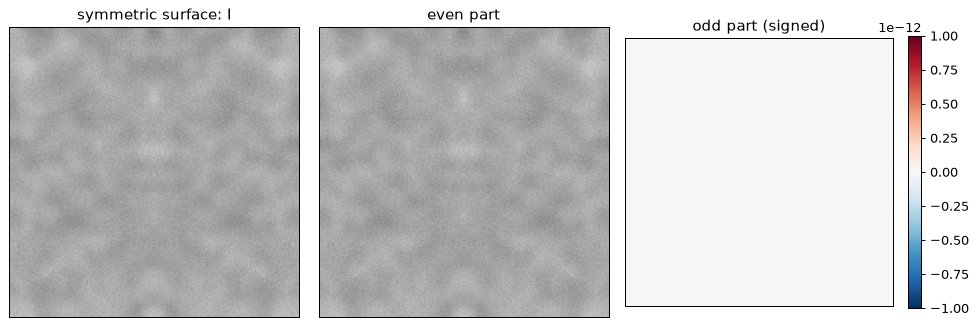

symmetric surface      S = 1.0000   S (mean removed) = 1.0000   odd energy fraction = 0.00e+00


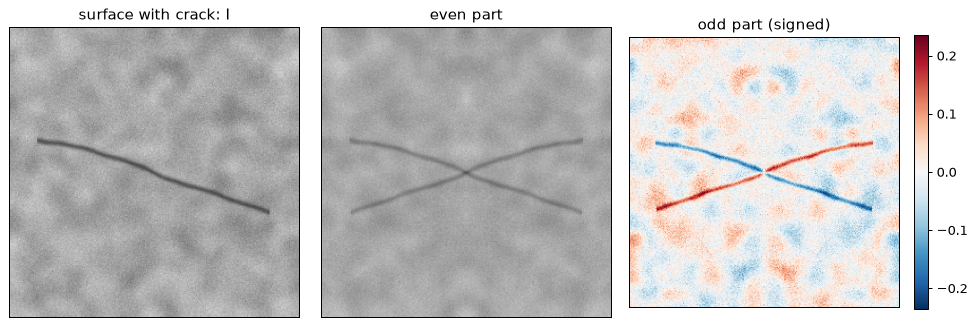

surface with crack     S = 0.8730   S (mean removed) = -0.4009   odd energy fraction = 4.03e-03


In [3]:
sample = io.generate_synthetic_crack(seed=SEED)          # asymmetric: one diagonal crack
symmetric = io.generate_symmetric_image(seed=SEED)       # crack-free, mirror-symmetric

def show_decomposition(image, title):
    even, odd = symmetry.even_odd_decompose(image, "horizontal")
    lim = max(np.abs(odd).max(), 1e-12)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
    axes[0].imshow(image, cmap="gray", vmin=0, vmax=1); axes[0].set_title(f"{title}: I")
    axes[1].imshow(even, cmap="gray", vmin=0, vmax=1);  axes[1].set_title("even part")
    im = axes[2].imshow(odd, cmap="RdBu_r", vmin=-lim, vmax=lim); axes[2].set_title("odd part (signed)")
    fig.colorbar(im, ax=axes[2], fraction=0.046)
    for ax in axes: ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); plt.show()

    S = symmetry.symmetry_score(image, "horizontal")
    S0 = symmetry.symmetry_score(image, "horizontal", remove_mean=True)
    print(f"{title:<22} S = {S:.4f}   S (mean removed) = {S0:.4f}   "
          f"odd energy fraction = {symmetry.odd_energy_fraction(image):.2e}")
    # Checks that hold for ANY image:
    assert np.allclose(even + odd, image, atol=1e-15)
    assert np.isclose((even**2).sum() + (odd**2).sum(), (image**2).sum())

show_decomposition(symmetric, "symmetric surface")
show_decomposition(sample.image, "surface with crack")

### Two things to notice

**The mean brightness dominates the plain score.** A gray surface is mostly a
constant, and a constant is perfectly symmetric. That is why the cracked image
still scores about 0.87, while the mean-removed score (which looks only at the
*pattern*) is strongly negative. Always say which one you report.

**The odd part of the cracked image is mostly texture, not crack.** A random
surface is never mirror-symmetric, so its texture leaks into the odd part too.
Symmetry only isolates a defect when the *undamaged* object is symmetric: a
machined specimen, a regular masonry bond, a beam photographed square-on.

The next cell builds that favourable case: a symmetric surface plus a crack.
The odd part then shows the crack and its sign-flipped mirror "ghost", and
almost nothing else.

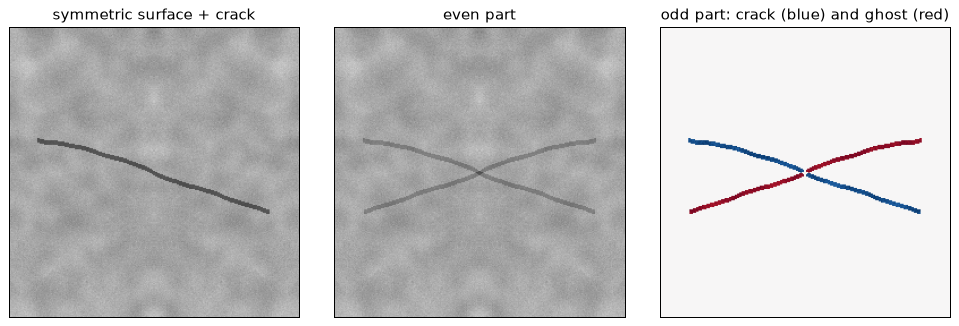

S before crack = 1.000000
S after  crack = 0.921903
The score drops, but a stain, a shadow or a bolt would lower it just the same.


In [4]:
cracked_symmetric = symmetric.copy()
cracked_symmetric[sample.mask] *= 0.5        # darken the crack pixels by 50 %

even, odd = symmetry.even_odd_decompose(cracked_symmetric, "horizontal")
lim = np.abs(odd).max()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].imshow(cracked_symmetric, cmap="gray", vmin=0, vmax=1); axes[0].set_title("symmetric surface + crack")
axes[1].imshow(even, cmap="gray", vmin=0, vmax=1); axes[1].set_title("even part")
axes[2].imshow(odd, cmap="RdBu_r", vmin=-lim, vmax=lim); axes[2].set_title("odd part: crack (blue) and ghost (red)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

print(f"S before crack = {symmetry.symmetry_score(symmetric):.6f}")
print(f"S after  crack = {symmetry.symmetry_score(cracked_symmetric):.6f}")
print("The score drops, but a stain, a shadow or a bolt would lower it just the same.")

## 3. Crack detection

The pipeline in `crack_photonics.cli.analyze` has four timed stages.

| Stage | What it does | Module |
|---|---|---|
| preprocessing | min-max normalise, light Gaussian blur | `io.preprocess` |
| symmetry analysis | scores and even/odd parts for both mirrors | `symmetry` |
| edge detection | simplified PST phase, robust threshold | `pst_edges` |
| metric extraction | dark-residual segmentation, skeleton, metrics | `crack_metrics` |

**Edges are not the crack.** The PST-style detector marks the two *banks* of
the crack, where brightness changes. The crack *fill* comes from a separate,
very plain rule: a pixel is crack if it is clearly darker than a wide Gaussian
average of its neighbourhood. The edge map is then used as independent
supporting evidence in the confidence score.

**Metrics.**

- area % = crack pixels / all pixels x 100
- length = length of the one-pixel-wide skeleton (Zhang-Suen thinning),
  counting 1 per straight step and $\sqrt2$ per diagonal step
- mean width = area / length; max width from the distance transform
- orientation = principal axis (PCA) of the crack pixel cloud, in $[0^\circ,180^\circ)$,
  counter-clockwise from the picture's $+x$ axis
- connected components = number of separate pieces
- confidence = $0.4\,\text{contrast}+0.3\,\text{edge support}+0.3\,\text{elongation}$,
  a hand-built heuristic, **not** a calibrated probability

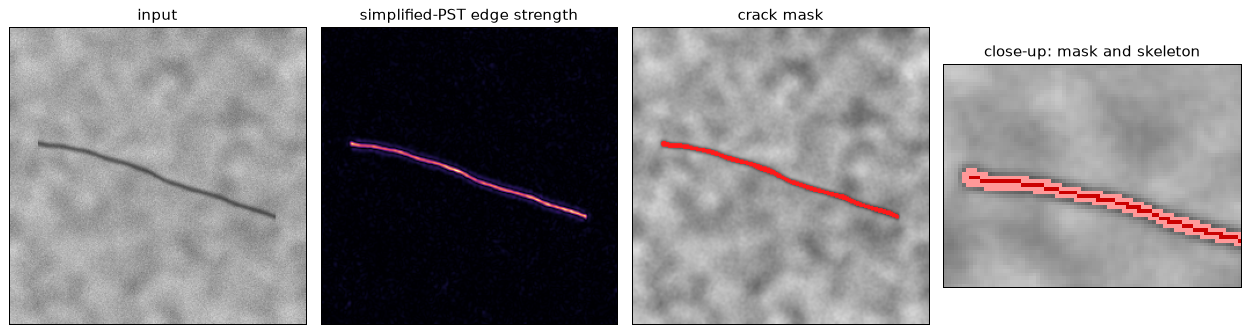

metric                        measured   ground truth
area (% of pixels)               1.239          1.251
length (px)                      210.9          215.6
mean width (px)                   3.85           4.00
max width (px)                    4.66               
orientation (deg)                161.7               
connected components                 1              1
confidence (heuristic)            1.00               

mask overlap with ground truth (IoU) = 0.92


In [5]:
result = analyze(sample.image)
mask, crack = result["mask"], result["crack"]
skeleton = crack_metrics.skeletonize(mask)

overlay = np.dstack([result["preprocessed"]] * 3); overlay[mask] = [1, 0.1, 0.1]
zoom = (slice(70, 130), slice(20, 100))      # rows, cols of a close-up

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
axes[0].imshow(sample.image, cmap="gray", vmin=0, vmax=1); axes[0].set_title("input")
axes[1].imshow(result["edge_strength"], cmap="magma");       axes[1].set_title("simplified-PST edge strength")
axes[2].imshow(overlay);                                      axes[2].set_title("crack mask")
close = np.dstack([result["preprocessed"][zoom]] * 3)
close[mask[zoom]] = [1, 0.6, 0.6]; close[skeleton[zoom]] = [0.8, 0, 0]
axes[3].imshow(close);                                        axes[3].set_title("close-up: mask and skeleton")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

iou = (mask & sample.mask).sum() / (mask | sample.mask).sum()
truth_area = crack_metrics.crack_area_percent(sample.mask)
print(f"{'metric':<26}{'measured':>12}{'ground truth':>15}")
print(f"{'area (% of pixels)':<26}{crack['crack_area_percent']:>12.3f}{truth_area:>15.3f}")
print(f"{'length (px)':<26}{crack['crack_length_px']:>12.1f}{sample.true_length_px:>15.1f}")
print(f"{'mean width (px)':<26}{crack['mean_width_px']:>12.2f}{sample.true_width_px:>15.2f}")
print(f"{'max width (px)':<26}{crack['max_width_px']:>12.2f}{'':>15}")
print(f"{'orientation (deg)':<26}{crack['orientation_deg']:>12.1f}{'':>15}")
print(f"{'connected components':<26}{crack['connected_components']:>12d}{1:>15d}")
print(f"{'confidence (heuristic)':<26}{crack['confidence']:>12.2f}{'':>15}")
print(f"\nmask overlap with ground truth (IoU) = {iou:.2f}")

The measured length agrees with the ground-truth centreline to within a few
percent, not exactly. Two effects pull in opposite directions: the threshold
trims the faint ends of the crack (shorter), and counting 0/45/90-degree pixel
steps along a line at another angle overestimates (by up to about 8 % near
22.5 degrees). They partly cancel here; on another image they may not. Report
the uncertainty; do not hide it.

### Pixels are not millimetres

The code never guesses a scale. Until you supply `pixel_size_mm` from a ruler
or crack-gauge card photographed in the plane of the crack, the millimetre
fields are `None`. The value 0.1 mm/pixel below is **made up** to show the
conversion.

In [6]:
no_scale = crack_metrics.compute_metrics(mask, result["preprocessed"], result["edge_mask"])
with_scale = crack_metrics.compute_metrics(mask, result["preprocessed"], result["edge_mask"],
                                           pixel_size_mm=0.1)
print("without scale:", no_scale["crack_length_mm"], "|", no_scale["units_note"])
print(f"with 0.1 mm/px: length = {with_scale['crack_length_mm']:.1f} mm, "
      f"mean width = {with_scale['mean_width_mm']:.2f} mm, max width = {with_scale['max_width_mm']:.2f} mm")

without scale: None | No scale reference given: lengths are in pixels. Pass --pixel-size-mm to convert.
with 0.1 mm/px: length = 21.1 mm, mean width = 0.39 mm, max width = 0.47 mm


## 4. Timing and computational complexity

Every stage is wrapped in `time.perf_counter()` by `StageTimer`. Let $N$ be
the number of pixels.

| Stage | Dominant operation | Time | Memory |
|---|---|---|---|
| image loading | PNG decode | $O(N)$ | $O(N)$ |
| preprocessing | separable Gaussian blur, kernel width $k$ | $O(Nk)$ | $O(N)$ |
| symmetry analysis | flips, sums, norms | $O(N)$ | $O(N)$ |
| edge detection | two 2-D FFTs | $O(N\log N)$ | $O(N)$ |
| metric extraction | blur + labelling + thinning with $p$ passes | $O(Nk)+O(Np)$ | $O(N)$ |

The thinning pass count $p$ is about half the widest crack width in pixels,
so it grows with resolution if the crack gets more pixels across.

Asymptotically the FFT's $N\log N$ should win. The experiment below checks
what actually happens at sizes you would use. One small warm-up run pays the
one-time costs (imports, FFT planning) first. Then each size is run three
times and the fastest time of each stage is kept, which reduces noise from
other programs.

       size       preprocessing   symmetry_analysis      edge_detection   metric_extraction    sum (ms)
  128x128               0.22 ms             7.05 ms             2.93 ms             4.83 ms       15.02
  256x256               1.40 ms             2.52 ms            11.90 ms            13.44 ms       29.26
  512x512               2.79 ms             5.28 ms            34.63 ms            40.79 ms       83.49
 1024x1024             10.94 ms            29.00 ms           124.72 ms           115.61 ms      280.27


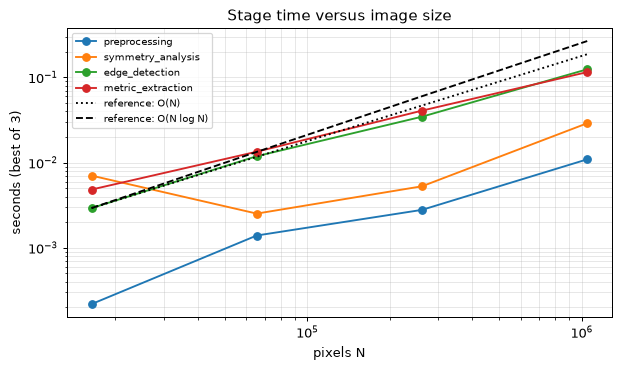

log-log slope (1.0 = linear in N): {'preprocessing': 0.9, 'symmetry_analysis': 0.36, 'edge_detection': 0.89, 'metric_extraction': 0.77}


In [7]:
sizes = [128, 256, 512, 1024]
keys = [f"{name}_s" for name in STAGE_NAMES if name != "image_loading"]   # no file is loaded here
table = {key: [] for key in keys}

analyze(io.generate_synthetic_crack(shape=(64, 64), seed=SEED).image)    # warm-up, not timed

for n in sizes:
    image = io.generate_synthetic_crack(shape=(n, n), seed=SEED).image
    runs = []
    for _ in range(3):
        timer = StageTimer()
        analyze(image, timer=timer)
        timer.stop()
        runs.append(timer.report())
    for key in keys:
        table[key].append(min(run[key] for run in runs))

print(f"{'size':>11}" + "".join(f"{k[:-2]:>20}" for k in keys) + f"{'sum (ms)':>12}")
for i, n in enumerate(sizes):
    row = [table[k][i] * 1e3 for k in keys]
    print(f"{n:>5}x{n:<5}" + "".join(f"{v:>17.2f} ms" for v in row) + f"{sum(row):>12.2f}")

N = np.array(sizes, dtype=float) ** 2
fig, ax = plt.subplots(figsize=(7, 4.2))
for key in keys:
    ax.loglog(N, table[key], "o-", label=key[:-2])
ref = table["edge_detection_s"][0]
ax.loglog(N, ref * N / N[0], "k:", label="reference: O(N)")
ax.loglog(N, ref * N * np.log(N) / (N[0] * np.log(N[0])), "k--", label="reference: O(N log N)")
ax.set(xlabel="pixels N", ylabel="seconds (best of 3)", title="Stage time versus image size")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

slopes = {k[:-2]: float(np.polyfit(np.log(N), np.log(table[k]), 1)[0]) for k in keys}
print("log-log slope (1.0 = linear in N):", {k: round(v, 2) for k, v in slopes.items()})

**Reading the result.** Your numbers will differ from anyone else's: they
depend on the CPU, the FFT and BLAS builds, memory speed and what else is
running. Look at the *slopes*. A slope near 1 means time grows in proportion
to the pixel count. A slope below 1 means fixed per-call overhead still matters
at the small sizes. Over a range this small, $N$ and $N\log N$ are hard to
tell apart, and a slope above 1 often comes from the image no longer fitting
in the CPU cache rather than from the algorithm.

Practical consequences:

- Timings in `timing.json` include one-time costs (imports, first FFT plan) on
  a first run. Benchmark with repeats.
- A GPU would mainly help the FFT stage. This project deliberately has no GPU
  code path, so results are the same on every machine.

## 5. Physics-inspired algorithm versus data-driven neural network

| | Physics-inspired (this repository) | Data-driven neural network |
|---|---|---|
| Where the knowledge comes from | Equations you can write down: reflection, dispersion-like phase filter, "cracks are dark and thin" | Thousands of labelled examples |
| Parameters | About ten, each with a physical meaning ($S$, $W$, blur widths, thresholds) | Millions of weights with no individual meaning |
| Training data | None | Large, labelled, representative; expensive to collect |
| Inspectability | Every intermediate image can be plotted and explained | Needs extra tools; explanations are approximate |
| Failure style | Predictable: anything dark, thin and edgy is called a crack | Hard to predict outside the training distribution |
| Context | None: cannot tell a crack from a joint, a shadow or a pencil line | Can learn context if the data contain it |
| Accuracy on messy real surfaces | Usually lower | Usually higher, *if* trained and tested properly |
| Hardware | Any laptop CPU | CPU for inference; GPU helps training |
| Evaluation trap | Thresholds tuned on the same images you report | **Data leakage**: train and test crops from the same specimen |

Neither is "better". A physics-inspired method is a transparent baseline and a
good feature extractor. A network is a flexible function fitted to data, and
it is only as trustworthy as its data and its test protocol.

**Data leakage, concretely.** If you cut one photographed beam into 200
patches and randomly put 160 in "train" and 40 in "test", the test patches
share the same concrete, lighting, camera and even the same crack. The network
can score 99 % and still fail on the next beam. Split by **specimen**: every
patch from a given specimen goes entirely into train or entirely into test.

The cell below shows the "no context" failure of the method in this notebook:
a straight saw-cut joint, which is not damage, gets a confident crack report.

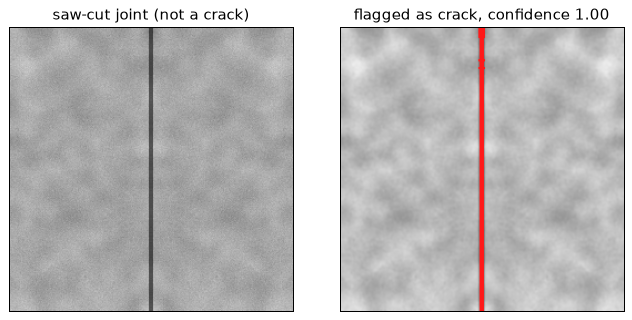

area 1.61 %, length 251 px, orientation 90 deg, confidence 1.00
left-right symmetry score S = 1.0000 (the joint sits on the mirror line, so symmetry does not notice it at all)


In [8]:
joint = io.generate_symmetric_image(seed=SEED).copy()
joint[:, 126:130] *= 0.45                       # a straight, dark, vertical construction joint
joint_result = analyze(joint)
jc = joint_result["crack"]

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
axes[0].imshow(joint, cmap="gray", vmin=0, vmax=1); axes[0].set_title("saw-cut joint (not a crack)")
ov = np.dstack([joint_result["preprocessed"]] * 3); ov[joint_result["mask"]] = [1, 0.1, 0.1]
axes[1].imshow(ov); axes[1].set_title(f"flagged as crack, confidence {jc['confidence']:.2f}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

print(f"area {jc['crack_area_percent']:.2f} %, length {jc['crack_length_px']:.0f} px, "
      f"orientation {jc['orientation_deg']:.0f} deg, confidence {jc['confidence']:.2f}")
print(f"left-right symmetry score S = {joint_result['symmetry']['horizontal']['score']:.4f} "
      "(the joint sits on the mirror line, so symmetry does not notice it at all)")

The joint is dark, thin and has sharp edges, so every cue fires. The symmetry
score stays near 1 because the joint lies on the mirror line. Two lessons:

1. **Image symmetry is a feature, not proof of a crack.** Asymmetry can come
   from anything, and a symmetric defect is invisible to it.
2. A confident number from an algorithm is not a measurement until it has been
   checked against calibrated data from the material you care about.

## Limits, in one place

- Synthetic images test the *code*. They say nothing about performance on
  real concrete, asphalt or masonry.
- Lengths and widths are in pixels until you supply a scale reference.
- The PST-style detector is an educational approximation, not laboratory
  photonic hardware.
- If you move from simulation to an optical bench, high-power sources require
  your institution's laser-safety procedures and training.

## Things to try

1. Change `phase_strength` and `warp_strength` in `pst_edges.detect_edges` and
   watch the edge map.
2. Mirror the crack image top-bottom and predict the new orientation angle
   before you run it.
3. Add a brightness ramp (uneven lighting) to the image. Which stage breaks
   first?
4. Photograph a cracked paving slab with a ruler in the frame, measure
   millimetres per pixel, and run the command-line tool with `--pixel-size-mm`.